In [46]:
import pandas as pd
from pathlib import Path

In [47]:
processed_path = Path("../data/processed")

glucose = pd.read_csv(
    processed_path / "glucose_level.csv",
    parse_dates=["ts"]
)

meal = pd.read_csv(
    processed_path / "meal.csv",
    parse_dates=["ts"]
)

bolus = pd.read_csv(
    processed_path / "bolus.csv",
    parse_dates=["ts_begin"]
)

basal = pd.read_csv(
    processed_path / "basal.csv",
    parse_dates=["ts"]
)

temp_basal = pd.read_csv(
    processed_path / "temp_basal.csv",
    parse_dates=["ts_begin"]
)

exercise = pd.read_csv(
    processed_path / "exercise.csv",
    parse_dates=["ts"]
)

In [48]:
print(glucose.shape)
print(meal.shape)
print(bolus.shape)

(65535, 4)
(702, 5)
(1568, 6)


In [49]:
glucose = glucose.rename(columns = {
    'ts': 'timestamp',
    'value': 'glucose_value'
})

meal = meal.rename(columns = {
    'ts': 'timestamp',
    'carbs': 'meal_carbs',
    'type': 'meal_type'
})

bolus = bolus.rename(columns = {
    'ts_begin': 'timestamp',
    'dose': 'bolus_dose',
    'type': 'bolus_type'
})

basal = basal.rename(columns = {
    'ts': 'timestamp',
    'value': 'basal_value'
})

temp_basal = temp_basal.rename(columns = {
    'ts_begin': 'timestamp',
    'value': 'temp_basal_value'
})

exercise = exercise.rename(columns = {
    'ts': 'timestamp',
    'type': 'exercise_type',
    'duration': 'exercise_duration',
    'intensity': 'exercise_intensity'
})

In [50]:
datasets = [
    glucose,
    meal,
    bolus,
    basal,
    temp_basal,
    exercise
]

for df in datasets:
    df.sort_values(
        ['Patient', 'timestamp'],
        inplace=True
    )

In [51]:
merged = glucose.copy()

merged.head()

,Patient,Section,timestamp,glucose_value
43635,540-ws-training,glucose_level,2027-05-19 11:36:29,76
43638,540-ws-training,glucose_level,2027-05-19 11:41:29,72
43641,540-ws-training,glucose_level,2027-05-19 11:46:29,68
43644,540-ws-training,glucose_level,2027-05-19 11:51:29,65
43647,540-ws-training,glucose_level,2027-05-19 11:56:29,63


In [52]:
merged = pd.merge_asof(
    merged.sort_values("timestamp"),
    meal.sort_values("timestamp"),
    on="timestamp",
    by="Patient",
    direction="backward"
)

merged.head()

,Patient,Section_x,timestamp,glucose_value,Section_y,meal_type,meal_carbs
0,552-ws-training,glucose_level,2025-04-16 11:17:05,95,NaN,NaN,NaN
1,552-ws-training,glucose_level,2025-04-16 11:22:05,86,NaN,NaN,NaN
2,552-ws-training,glucose_level,2025-04-16 11:27:05,81,NaN,NaN,NaN
3,552-ws-training,glucose_level,2025-04-16 11:32:05,81,NaN,NaN,NaN
4,552-ws-training,glucose_level,2025-04-16 11:37:05,82,NaN,NaN,NaN


In [53]:
print(merged.shape)
print(merged.columns)

(65535, 7)
Index(['Patient', 'Section_x', 'timestamp', 'glucose_value', 'Section_y',
       'meal_type', 'meal_carbs'],
      dtype='str')


In [54]:
print(merged["meal_carbs"].notna().sum())

64026


In [55]:
merged[merged["meal_carbs"].notna()].head(10)

,Patient,Section_x,timestamp,glucose_value,Section_y,meal_type,meal_carbs
81,552-ws-training,glucose_level,2025-04-16 18:02:06,228,meal,Dinner,30.0
82,552-ws-training,glucose_level,2025-04-16 18:07:06,232,meal,Dinner,30.0
83,552-ws-training,glucose_level,2025-04-16 18:12:06,234,meal,Dinner,30.0
84,552-ws-training,glucose_level,2025-04-16 18:17:06,233,meal,Dinner,30.0
85,552-ws-training,glucose_level,2025-04-16 18:22:06,234,meal,Dinner,30.0
86,552-ws-training,glucose_level,2025-04-16 18:27:06,233,meal,Dinner,30.0
87,552-ws-training,glucose_level,2025-04-16 18:32:06,230,meal,Dinner,30.0
88,552-ws-training,glucose_level,2025-04-16 18:37:06,235,meal,Dinner,30.0
89,552-ws-training,glucose_level,2025-04-16 18:42:06,242,meal,Dinner,30.0
90,552-ws-training,glucose_level,2025-04-16 18:47:06,241,meal,Dinner,30.0


In [56]:
merged = merged.drop(
    columns=["Section_x", "Section_y"],
    errors="ignore"
)

In [57]:
print(merged.columns.tolist())

['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs']


In [58]:
print(bolus.columns.tolist())

['Patient', 'Section', 'timestamp', 'ts_end', 'bolus_type', 'bolus_dose']


In [59]:
bolus = bolus[[
    "Patient",
    "timestamp",
    "bolus_type",
    "bolus_dose"
]].copy()

In [60]:
# def merge_patient_asof(left_df, right_df):

#     merged_list = []

#     for patient in sorted(left_df["Patient"].unique()):

#         left = (
#             left_df[left_df["Patient"] == patient]
#             .sort_values("timestamp")
#             .reset_index(drop=True)
#         )

#         right = (
#             right_df[right_df["Patient"] == patient]
#             .sort_values("timestamp")
#             .reset_index(drop=True)
#         )

#         temp = pd.merge_asof(
#             left,
#             right,
#             on="timestamp",
#             direction="backward"
#         )

#         merged_list.append(temp)

#     return pd.concat(merged_list, ignore_index=True)

In [61]:
def merge_patient_asof(left_df, right_df):

    merged_list = []

    for patient in sorted(left_df["Patient"].unique()):

        left = (
            left_df[left_df["Patient"] == patient]
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        right = (
            right_df[right_df["Patient"] == patient]
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        # Remove Patient column from the right dataframe
        right = right.drop(columns=["Patient"], errors="ignore")

        temp = pd.merge_asof(
            left,
            right,
            on="timestamp",
            direction="backward"
        )

        merged_list.append(temp)

    return pd.concat(merged_list, ignore_index=True)

In [62]:
merged = merge_patient_asof(merged, bolus)

In [63]:
print(merged.columns.tolist())

['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose']


In [64]:
def merge_patient_asof(left_df, right_df):

    merged_list = []

    for patient in sorted(left_df["Patient"].unique()):

        left = (
            left_df[left_df["Patient"] == patient]
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        right = (
            right_df[right_df["Patient"] == patient]
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        # Remove Patient column from the right dataframe
        right = right.drop(columns=["Patient"], errors="ignore")

        temp = pd.merge_asof(
            left,
            right,
            on="timestamp",
            direction="backward"
        )

        merged_list.append(temp)

    return pd.concat(merged_list, ignore_index=True)

In [65]:
print(basal.columns.tolist())

['Patient', 'Section', 'timestamp', 'basal_value']


In [66]:
basal = basal[[
    'Patient',
    'timestamp',
    'basal_value'
]].copy()

In [67]:
print(basal.head())
print(basal.columns.tolist())

             Patient           timestamp  basal_value
228  540-ws-training 2027-05-19 00:00:00         0.80
229  540-ws-training 2027-05-19 05:00:00         1.05
230  540-ws-training 2027-05-19 09:00:00         0.95
231  540-ws-training 2027-05-19 14:00:00         0.40
232  540-ws-training 2027-05-22 00:00:00         0.80
['Patient', 'timestamp', 'basal_value']


In [68]:
merged = merge_patient_asof(merged, basal)

In [69]:
if "Patient_x" in merged.columns:
    merged = merged.rename(columns={"Patient_x": "Patient"})

if "Patient_y" in merged.columns:
    merged = merged.drop(columns=["Patient_y"])

In [70]:
print(merged.columns.tolist())

['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value']


In [71]:
merged.head(10)

,Patient,timestamp,glucose_value,meal_type,meal_carbs,bolus_type,bolus_dose,basal_value
0,540-ws-training,2027-05-19 11:36:29,76,NaN,NaN,normal,0.8,0.95
1,540-ws-training,2027-05-19 11:41:29,72,NaN,NaN,normal,0.8,0.95
2,540-ws-training,2027-05-19 11:46:29,68,NaN,NaN,normal,0.8,0.95
3,540-ws-training,2027-05-19 11:51:29,65,NaN,NaN,normal,0.8,0.95
4,540-ws-training,2027-05-19 11:56:29,63,NaN,NaN,normal,0.8,0.95
5,540-ws-training,2027-05-19 12:01:29,66,NaN,NaN,normal,0.8,0.95
6,540-ws-training,2027-05-19 12:06:29,71,NaN,NaN,normal,0.8,0.95
7,540-ws-training,2027-05-19 12:11:29,78,NaN,NaN,normal dual,5.5,0.95
8,540-ws-training,2027-05-19 12:16:29,90,NaN,NaN,normal dual,5.5,0.95
9,540-ws-training,2027-05-19 12:21:29,99,NaN,NaN,normal dual,5.5,0.95


In [72]:
print(merged.columns.tolist())

['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value']


In [73]:
temp_basal = temp_basal[[
    'Patient',
    'timestamp',
    'temp_basal_value'
]].copy()

In [74]:
print(temp_basal.columns.tolist())

['Patient', 'timestamp', 'temp_basal_value']


In [75]:
merged = merge_patient_asof(merged, temp_basal)

In [76]:
if "Patient_x" in merged.columns:
    merged = merged.rename(columns={"Patient_x": "Patient"})

if "Patient_y" in merged.columns:
    merged = merged.drop(columns=["Patient_y"])

In [77]:
print(merged.columns.tolist())

['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value', 'temp_basal_value']


In [78]:
exercise = exercise[[
    'Patient',
    'timestamp',
    'exercise_type',
    'exercise_duration',
    'exercise_intensity'
]].copy()

In [79]:
merged = merge_patient_asof(merged, exercise)

In [80]:
print(merged.columns.tolist())

['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_type', 'exercise_duration', 'exercise_intensity']


In [81]:
finger_stick_path = processed_path / "finger_stick.csv"

if not finger_stick_path.exists():
    raise FileNotFoundError(f"{finger_stick_path} not found. Load the finger_stick dataset first.")

finger_stick = pd.read_csv(
    finger_stick_path,
    parse_dates=["ts"]
).rename(columns={"ts": "timestamp"})

finger_stick = finger_stick[[
    "Patient",
    "timestamp",
    "value"
]].copy()

In [82]:
merged = merge_patient_asof(merged, finger_stick)

In [83]:
print(merged.columns.tolist())

['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_type', 'exercise_duration', 'exercise_intensity', 'value']


In [84]:
# ============================================
# STEP 1: CHECK CURRENT MERGED DATASET
# ============================================

print("Merged dataset shape:")
print(merged.shape)

print("\nColumns:")
print(merged.columns.tolist())

print("\nFirst 10 rows:")
display(merged.head(10))

print("\nMissing values:")
display(merged.isnull().sum().sort_values(ascending=False))

print("\nPatients:")
print("Number of patients:", merged["Patient"].nunique())

print("\nDate range:")
print("Start:", merged["timestamp"].min())
print("End:", merged["timestamp"].max())

Merged dataset shape:
(65535, 13)

Columns:
['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_type', 'exercise_duration', 'exercise_intensity', 'value']

First 10 rows:


,Patient,timestamp,glucose_value,meal_type,meal_carbs,bolus_type,bolus_dose,basal_value,temp_basal_value,exercise_type,exercise_duration,exercise_intensity,value
0,540-ws-training,2027-05-19 11:36:29,76,NaN,NaN,normal,0.8,0.95,NaN,NaN,NaN,NaN,80.0
1,540-ws-training,2027-05-19 11:41:29,72,NaN,NaN,normal,0.8,0.95,NaN,NaN,NaN,NaN,80.0
2,540-ws-training,2027-05-19 11:46:29,68,NaN,NaN,normal,0.8,0.95,NaN,NaN,NaN,NaN,80.0
3,540-ws-training,2027-05-19 11:51:29,65,NaN,NaN,normal,0.8,0.95,NaN,NaN,NaN,NaN,80.0
4,540-ws-training,2027-05-19 11:56:29,63,NaN,NaN,normal,0.8,0.95,NaN,NaN,NaN,NaN,80.0
5,540-ws-training,2027-05-19 12:01:29,66,NaN,NaN,normal,0.8,0.95,NaN,NaN,NaN,NaN,80.0
6,540-ws-training,2027-05-19 12:06:29,71,NaN,NaN,normal,0.8,0.95,NaN,NaN,NaN,NaN,80.0
7,540-ws-training,2027-05-19 12:11:29,78,NaN,NaN,normal dual,5.5,0.95,NaN,NaN,NaN,NaN,80.0
8,540-ws-training,2027-05-19 12:16:29,90,NaN,NaN,normal dual,5.5,0.95,NaN,NaN,NaN,NaN,80.0
9,540-ws-training,2027-05-19 12:21:29,99,NaN,NaN,normal dual,5.5,0.95,NaN,NaN,NaN,NaN,80.0



Missing values:


exercise_type         35807
exercise_duration     35807
exercise_intensity    35807
temp_basal_value       6926
meal_type              1509
meal_carbs             1509
bolus_type              241
bolus_dose              241
value                   179
Patient                   0
timestamp                 0
glucose_value             0
basal_value               0
dtype: int64


Patients:
Number of patients: 6

Date range:
Start: 2025-04-16 11:17:05
End: 2027-07-03 23:56:44


In [85]:
sleep = pd.read_csv(
    processed_path / "sleep.csv"
)

print("Sleep shape:")
print(sleep.shape)

print("\nSleep columns:")
print(sleep.columns.tolist())

print("\nFirst 10 rows:")
display(sleep.head(10))

print("\nData types:")
print(sleep.dtypes)

Sleep shape:
(150, 5)

Sleep columns:
['Patient', 'Section', 'ts_begin', 'ts_end', 'quality']

First 10 rows:


,Patient,Section,ts_begin,ts_end,quality
0,552-ws-training,sleep,2025-04-17 05:36:00,2025-04-16 23:00:00,2
1,552-ws-training,sleep,2025-04-23 06:00:00,2025-04-22 22:32:00,3
2,552-ws-training,sleep,2025-04-24 05:35:00,2025-04-23 23:00:00,2
3,552-ws-training,sleep,2025-04-25 09:32:00,2025-04-25 00:30:00,3
4,552-ws-training,sleep,2025-04-26 09:39:00,2025-04-25 22:39:00,3
5,552-ws-training,sleep,2025-04-27 09:00:00,2025-04-26 23:28:00,3
6,552-ws-training,sleep,2025-04-29 06:31:00,2025-04-28 23:31:00,1
7,552-ws-training,sleep,2025-04-30 05:30:00,2025-04-29 22:30:00,2
8,552-ws-training,sleep,2025-05-01 05:35:00,2025-04-30 23:15:00,3
9,552-ws-training,sleep,2025-05-06 05:40:00,2025-05-05 22:52:00,3



Data types:
Patient       str
Section       str
ts_begin      str
ts_end        str
quality     int64
dtype: object


In [86]:
# ============================================
# STEP 2: PREPARE AND MERGE SLEEP DATA
# ============================================

# Load sleep dataset
sleep = pd.read_csv(
    processed_path / "sleep.csv"
)

# Convert timestamps from strings to datetime
sleep["ts_begin"] = pd.to_datetime(sleep["ts_begin"])
sleep["ts_end"] = pd.to_datetime(sleep["ts_end"])

# Calculate sleep duration in hours
sleep["sleep_duration_hours"] = (
    sleep["ts_begin"] - sleep["ts_end"]
).dt.total_seconds() / 3600

# Rename columns
sleep = sleep.rename(columns={
    "ts_begin": "timestamp",
    "quality": "sleep_quality"
})

# Keep only required columns
sleep = sleep[[
    "Patient",
    "timestamp",
    "sleep_duration_hours",
    "sleep_quality"
]].copy()

# Sort correctly
sleep = sleep.sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

print("Sleep dataset prepared successfully.")

print("\nSleep shape:")
print(sleep.shape)

print("\nSleep columns:")
print(sleep.columns.tolist())

print("\nSleep sample:")
display(sleep.head(10))

print("\nSleep duration statistics:")
print(sleep["sleep_duration_hours"].describe())

Sleep dataset prepared successfully.

Sleep shape:
(150, 4)

Sleep columns:
['Patient', 'timestamp', 'sleep_duration_hours', 'sleep_quality']

Sleep sample:


,Patient,timestamp,sleep_duration_hours,sleep_quality
0,544-ws-training,2027-05-12 06:16:00,7.233333,2
1,544-ws-training,2027-05-13 06:26:00,8.583333,2
2,544-ws-training,2027-05-14 06:30:00,6.900000,2
3,544-ws-training,2027-05-15 07:28:00,9.150000,2
4,544-ws-training,2027-05-16 07:05:00,8.500000,1
5,544-ws-training,2027-05-17 05:10:00,7.150000,2
6,544-ws-training,2027-05-18 06:11:00,8.550000,1
7,544-ws-training,2027-05-19 06:12:00,8.216667,2
8,544-ws-training,2027-05-20 06:14:00,7.283333,2
9,544-ws-training,2027-05-21 06:04:00,6.533333,3



Sleep duration statistics:
count    150.000000
mean       7.634667
std        1.199003
min        5.000000
25%        7.000000
50%        7.458333
75%        8.266667
max       11.700000
Name: sleep_duration_hours, dtype: float64


In [87]:
# ============================================
# STEP 2B: MERGE SLEEP WITH MAIN DATASET
# ============================================

merged = merge_patient_asof(merged, sleep)

print("Sleep merged successfully!")

print("\nMerged dataset shape:")
print(merged.shape)

print("\nMerged columns:")
print(merged.columns.tolist())

print("\nSleep data available:")
print("Sleep duration:", merged["sleep_duration_hours"].notna().sum())
print("Sleep quality:", merged["sleep_quality"].notna().sum())

print("\nUpdated missing values:")
display(
    merged.isnull().sum().sort_values(ascending=False)
)

Sleep merged successfully!

Merged dataset shape:
(65535, 15)

Merged columns:
['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_type', 'exercise_duration', 'exercise_intensity', 'value', 'sleep_duration_hours', 'sleep_quality']

Sleep data available:
Sleep duration: 51956
Sleep quality: 51956

Updated missing values:


exercise_type           35807
exercise_duration       35807
exercise_intensity      35807
sleep_duration_hours    13579
sleep_quality           13579
temp_basal_value         6926
meal_type                1509
meal_carbs               1509
bolus_type                241
bolus_dose                241
value                     179
Patient                     0
timestamp                   0
glucose_value               0
basal_value                 0
dtype: int64

In [88]:
# ============================================
# STEP 3: FINAL COLUMN CLEANUP
# ============================================

# Rename finger-stick glucose value
merged = merged.rename(columns={
    "value": "finger_stick_value"
})

# Remove accidental duplicate columns if any
merged = merged.loc[:, ~merged.columns.duplicated()]

print("Final columns:")
print(merged.columns.tolist())

print("\nFinal shape:")
print(merged.shape)

print("\nData types:")
print(merged.dtypes)

print("\nMissing values:")
display(
    merged.isnull().sum().sort_values(ascending=False)
)

Final columns:
['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_type', 'exercise_duration', 'exercise_intensity', 'finger_stick_value', 'sleep_duration_hours', 'sleep_quality']

Final shape:
(65535, 15)

Data types:
Patient                            str
timestamp               datetime64[us]
glucose_value                    int64
meal_type                          str
meal_carbs                     float64
bolus_type                         str
bolus_dose                     float64
basal_value                    float64
temp_basal_value               float64
exercise_type                      str
exercise_duration              float64
exercise_intensity             float64
finger_stick_value             float64
sleep_duration_hours           float64
sleep_quality                  float64
dtype: object

Missing values:


exercise_type           35807
exercise_duration       35807
exercise_intensity      35807
sleep_duration_hours    13579
sleep_quality           13579
temp_basal_value         6926
meal_type                1509
meal_carbs               1509
bolus_type                241
bolus_dose                241
finger_stick_value        179
Patient                     0
timestamp                   0
glucose_value               0
basal_value                 0
dtype: int64

In [89]:
# ============================================
# STEP 4: ANALYZE GLUCOSE TIMELINE
# ============================================

# Sort by patient and time
merged = merged.sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

# Check glucose statistics
print("Glucose statistics:")
print(merged["glucose_value"].describe())

# Check glucose range
print("\nMinimum glucose:", merged["glucose_value"].min())
print("Maximum glucose:", merged["glucose_value"].max())

# Calculate time difference between glucose readings
merged["time_diff_minutes"] = (
    merged.groupby("Patient")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

print("\nTime difference between glucose readings:")
print(merged["time_diff_minutes"].describe())

# Most common intervals
print("\nMost common time intervals:")
print(
    merged["time_diff_minutes"]
    .value_counts()
    .head(10)
)

# Check duplicate patient/timestamp records
duplicates = merged.duplicated(
    subset=["Patient", "timestamp"]
).sum()

print("\nDuplicate Patient + Timestamp records:", duplicates)

Glucose statistics:
count    65535.000000
mean       157.700282
std         60.882019
min         40.000000
25%        112.000000
50%        149.000000
75%        193.000000
max        400.000000
Name: glucose_value, dtype: float64

Minimum glucose: 40
Maximum glucose: 400

Time difference between glucose readings:
count    65529.000000
mean         5.897042
std         33.560612
min          2.983333
25%          5.000000
50%          5.000000
75%          5.000000
max       3695.000000
Name: time_diff_minutes, dtype: float64

Most common time intervals:
time_diff_minutes
5.000000     64889
5.016667       316
5.033333        80
20.000000       27
15.000000       14
25.000000       12
45.000000       11
30.000000        9
55.000000        8
40.000000        7
Name: count, dtype: int64

Duplicate Patient + Timestamp records: 0


In [90]:
# ============================================
# STEP 5: CREATE 30-MINUTE FUTURE GLUCOSE TARGET
# ============================================

# Create a future glucose value based on the patient's
# time-series readings.

merged["target_glucose_30min"] = (
    merged.groupby("Patient")["glucose_value"]
    .shift(-6)
)

print("Target column created.")

print("\nTarget preview:")
display(
    merged[
        [
            "Patient",
            "timestamp",
            "glucose_value",
            "target_glucose_30min"
        ]
    ].head(15)
)

print("\nTarget missing values:")
print(
    merged["target_glucose_30min"].isnull().sum()
)

print("\nTarget statistics:")
print(
    merged["target_glucose_30min"].describe()
)

Target column created.

Target preview:


,Patient,timestamp,glucose_value,target_glucose_30min
0,540-ws-training,2027-05-19 11:36:29,76,71.0
1,540-ws-training,2027-05-19 11:41:29,72,78.0
2,540-ws-training,2027-05-19 11:46:29,68,90.0
3,540-ws-training,2027-05-19 11:51:29,65,99.0
4,540-ws-training,2027-05-19 11:56:29,63,110.0
5,540-ws-training,2027-05-19 12:01:29,66,121.0
6,540-ws-training,2027-05-19 12:06:29,71,131.0
7,540-ws-training,2027-05-19 12:11:29,78,137.0
8,540-ws-training,2027-05-19 12:16:29,90,140.0
9,540-ws-training,2027-05-19 12:21:29,99,140.0



Target missing values:
36

Target statistics:
count    65499.000000
mean       157.736194
std         60.874881
min         40.000000
25%        112.000000
50%        149.000000
75%        193.000000
max        400.000000
Name: target_glucose_30min, dtype: float64


In [91]:
# ============================================
# STEP 6: VALIDATE 30-MINUTE TARGET TIMING
# ============================================

# Get the timestamp of the glucose value 6 readings ahead
merged["target_timestamp_30min"] = (
    merged.groupby("Patient")["timestamp"]
    .shift(-6)
)

# Calculate actual time difference
merged["target_time_diff_minutes"] = (
    merged["target_timestamp_30min"] - merged["timestamp"]
).dt.total_seconds() / 60

print("Target time difference statistics:")
print(
    merged["target_time_diff_minutes"].describe()
)

print("\nMost common target time differences:")
print(
    merged["target_time_diff_minutes"]
    .round(1)
    .value_counts()
    .head(15)
)

print("\nExamples:")
display(
    merged[
        [
            "Patient",
            "timestamp",
            "glucose_value",
            "target_timestamp_30min",
            "target_glucose_30min",
            "target_time_diff_minutes"
        ]
    ].head(20)
)

Target time difference statistics:
count    65499.000000
mean        35.384715
std         82.099126
min         27.983333
25%         30.000000
50%         30.000000
75%         30.000000
max       3720.000000
Name: target_time_diff_minutes, dtype: float64

Most common target time differences:
target_time_diff_minutes
30.0     64076
45.0       159
70.0        84
40.0        84
50.0        72
55.0        60
80.0        48
65.0        42
90.0        36
35.0        36
60.0        30
75.0        30
105.0       24
170.0       24
95.0        24
Name: count, dtype: int64

Examples:


,Patient,timestamp,glucose_value,target_timestamp_30min,target_glucose_30min,target_time_diff_minutes
0,540-ws-training,2027-05-19 11:36:29,76,2027-05-19 12:06:29,71.0,30.0
1,540-ws-training,2027-05-19 11:41:29,72,2027-05-19 12:11:29,78.0,30.0
2,540-ws-training,2027-05-19 11:46:29,68,2027-05-19 12:16:29,90.0,30.0
3,540-ws-training,2027-05-19 11:51:29,65,2027-05-19 12:21:29,99.0,30.0
4,540-ws-training,2027-05-19 11:56:29,63,2027-05-19 12:26:29,110.0,30.0
5,540-ws-training,2027-05-19 12:01:29,66,2027-05-19 12:31:29,121.0,30.0
6,540-ws-training,2027-05-19 12:06:29,71,2027-05-19 12:36:29,131.0,30.0
7,540-ws-training,2027-05-19 12:11:29,78,2027-05-19 12:41:29,137.0,30.0
8,540-ws-training,2027-05-19 12:16:29,90,2027-05-19 12:46:29,140.0,30.0
9,540-ws-training,2027-05-19 12:21:29,99,2027-05-19 12:51:29,140.0,30.0


In [92]:
# ============================================
# STEP 7: CREATE CLEAN ML DATASET
# ============================================

# Keep only records where the target glucose
# is approximately 30 minutes in the future.
ml_data = merged[
    merged["target_time_diff_minutes"].between(28, 32)
].copy()

print("ML dataset created!")

print("\nOriginal merged dataset:")
print(merged.shape)

print("\nML dataset:")
print(ml_data.shape)

print("\nTarget timing:")
print(
    ml_data["target_time_diff_minutes"].describe()
)

print("\nTarget missing values:")
print(
    ml_data["target_glucose_30min"].isnull().sum()
)

print("\nPatients:")
print(
    ml_data["Patient"].nunique()
)

print("\nColumns:")
print(
    ml_data.columns.tolist()
)

ML dataset created!

Original merged dataset:
(65535, 19)

ML dataset:
(64088, 19)

Target timing:
count    64088.000000
mean        30.000754
std          0.014292
min         29.000000
25%         30.000000
50%         30.000000
75%         30.000000
max         31.000000
Name: target_time_diff_minutes, dtype: float64

Target missing values:
0

Patients:
6

Columns:
['Patient', 'timestamp', 'glucose_value', 'meal_type', 'meal_carbs', 'bolus_type', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_type', 'exercise_duration', 'exercise_intensity', 'finger_stick_value', 'sleep_duration_hours', 'sleep_quality', 'time_diff_minutes', 'target_glucose_30min', 'target_timestamp_30min', 'target_time_diff_minutes']


In [93]:
# ============================================
# STEP 8: FEATURE ENGINEERING
# ============================================

# Make a copy so the original merged dataset
# remains unchanged.
ml_data = ml_data.copy()

# --------------------------------------------
# 1. Previous glucose values
# --------------------------------------------

for lag in [1, 2, 3, 6]:
    ml_data[f"glucose_lag_{lag}"] = (
        ml_data.groupby("Patient")["glucose_value"]
        .shift(lag)
    )

# --------------------------------------------
# 2. Glucose trend
# --------------------------------------------

ml_data["glucose_change_5min"] = (
    ml_data["glucose_value"] -
    ml_data["glucose_lag_1"]
)

ml_data["glucose_change_15min"] = (
    ml_data["glucose_value"] -
    ml_data["glucose_lag_3"]
)

# --------------------------------------------
# 3. Time features
# --------------------------------------------

ml_data["hour"] = ml_data["timestamp"].dt.hour

ml_data["day_of_week"] = (
    ml_data["timestamp"].dt.dayofweek
)

# --------------------------------------------
# 4. Define ML features
# --------------------------------------------

feature_columns = [
    "glucose_value",
    "glucose_lag_1",
    "glucose_lag_2",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_change_5min",
    "glucose_change_15min",
    "meal_carbs",
    "bolus_dose",
    "basal_value",
    "temp_basal_value",
    "exercise_duration",
    "exercise_intensity",
    "sleep_duration_hours",
    "sleep_quality",
    "finger_stick_value",
    "hour",
    "day_of_week"
]

target_column = "target_glucose_30min"

# --------------------------------------------
# 5. Check the result
# --------------------------------------------

print("Feature engineering completed.")

print("\nNumber of features:", len(feature_columns))

print("\nFeatures:")
for feature in feature_columns:
    print("-", feature)

print("\nTarget:")
print("-", target_column)

print("\nFeature preview:")
display(
    ml_data[feature_columns].head(10)
)

Feature engineering completed.

Number of features: 18

Features:
- glucose_value
- glucose_lag_1
- glucose_lag_2
- glucose_lag_3
- glucose_lag_6
- glucose_change_5min
- glucose_change_15min
- meal_carbs
- bolus_dose
- basal_value
- temp_basal_value
- exercise_duration
- exercise_intensity
- sleep_duration_hours
- sleep_quality
- finger_stick_value
- hour
- day_of_week

Target:
- target_glucose_30min

Feature preview:


,glucose_value,glucose_lag_1,glucose_lag_2,glucose_lag_3,glucose_lag_6,glucose_change_5min,glucose_change_15min,meal_carbs,bolus_dose,basal_value,temp_basal_value,exercise_duration,exercise_intensity,sleep_duration_hours,sleep_quality,finger_stick_value,hour,day_of_week
0,76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.8,0.95,NaN,NaN,NaN,NaN,NaN,80.0,11,2
1,72,76.0,NaN,NaN,NaN,-4.0,NaN,NaN,0.8,0.95,NaN,NaN,NaN,NaN,NaN,80.0,11,2
2,68,72.0,76.0,NaN,NaN,-4.0,NaN,NaN,0.8,0.95,NaN,NaN,NaN,NaN,NaN,80.0,11,2
3,65,68.0,72.0,76.0,NaN,-3.0,-11.0,NaN,0.8,0.95,NaN,NaN,NaN,NaN,NaN,80.0,11,2
4,63,65.0,68.0,72.0,NaN,-2.0,-9.0,NaN,0.8,0.95,NaN,NaN,NaN,NaN,NaN,80.0,11,2
5,66,63.0,65.0,68.0,NaN,3.0,-2.0,NaN,0.8,0.95,NaN,NaN,NaN,NaN,NaN,80.0,12,2
6,71,66.0,63.0,65.0,76.0,5.0,6.0,NaN,0.8,0.95,NaN,NaN,NaN,NaN,NaN,80.0,12,2
7,78,71.0,66.0,63.0,72.0,7.0,15.0,NaN,5.5,0.95,NaN,NaN,NaN,NaN,NaN,80.0,12,2
8,90,78.0,71.0,66.0,68.0,12.0,24.0,NaN,5.5,0.95,NaN,NaN,NaN,NaN,NaN,80.0,12,2
9,99,90.0,78.0,71.0,65.0,9.0,28.0,NaN,5.5,0.95,NaN,NaN,NaN,NaN,NaN,80.0,12,2


In [94]:
# ============================================
# STEP 9: CHECK FEATURE MISSING VALUES
# ============================================

print("Missing values in ML features:")
missing_features = ml_data[feature_columns].isnull().sum()

display(
    missing_features
    .sort_values(ascending=False)
)

print("\nMissing percentage:")
missing_percentage = (
    ml_data[feature_columns]
    .isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(missing_percentage)

print("\nRows with missing feature values:")
print(
    ml_data[feature_columns]
    .isnull()
    .any(axis=1)
    .sum()
)

print("\nTarget missing values:")
print(
    ml_data[target_column].isnull().sum()
)

Missing values in ML features:


exercise_duration       35090
exercise_intensity      35090
sleep_duration_hours    13357
sleep_quality           13357
temp_basal_value         6788
meal_carbs               1485
bolus_dose                235
finger_stick_value        173
glucose_lag_6              36
glucose_lag_3              18
glucose_change_15min       18
glucose_lag_2              12
glucose_change_5min         6
glucose_lag_1               6
glucose_value               0
hour                        0
basal_value                 0
day_of_week                 0
dtype: int64


Missing percentage:


exercise_duration       54.752840
exercise_intensity      54.752840
sleep_duration_hours    20.841655
sleep_quality           20.841655
temp_basal_value        10.591686
meal_carbs               2.317126
bolus_dose               0.366683
finger_stick_value       0.269941
glucose_lag_6            0.056173
glucose_lag_3            0.028086
glucose_change_15min     0.028086
glucose_lag_2            0.018724
glucose_change_5min      0.009362
glucose_lag_1            0.009362
glucose_value            0.000000
hour                     0.000000
basal_value              0.000000
day_of_week              0.000000
dtype: float64


Rows with missing feature values:
41307

Target missing values:
0


In [95]:
# ============================================
# STEP 10: HANDLE MISSING VALUES
# ============================================

ml_data = ml_data.copy()

# --------------------------------------------
# 1. Event-based features
# --------------------------------------------

zero_fill_columns = [
    "meal_carbs",
    "bolus_dose",
    "temp_basal_value",
    "exercise_duration",
    "exercise_intensity"
]

for column in zero_fill_columns:
    ml_data[column] = ml_data[column].fillna(0)

# --------------------------------------------
# 2. Sleep information
# --------------------------------------------

sleep_columns = [
    "sleep_duration_hours",
    "sleep_quality"
]

ml_data[sleep_columns] = (
    ml_data.groupby("Patient")[sleep_columns]
    .ffill()
)

# --------------------------------------------
# 3. Finger-stick glucose
# --------------------------------------------

ml_data["finger_stick_value"] = (
    ml_data.groupby("Patient")["finger_stick_value"]
    .ffill()
)

# --------------------------------------------
# 4. Remove rows where glucose history
#    is unavailable
# --------------------------------------------

lag_columns = [
    "glucose_lag_1",
    "glucose_lag_2",
    "glucose_lag_3",
    "glucose_lag_6",
    "glucose_change_5min",
    "glucose_change_15min"
]

ml_data = ml_data.dropna(
    subset=lag_columns + [target_column]
).copy()

# --------------------------------------------
# 5. Check remaining missing values
# --------------------------------------------

print("Missing values after processing:")

display(
    ml_data[feature_columns]
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

print("\nFinal ML dataset shape:")
print(ml_data.shape)

print("\nTarget missing values:")
print(
    ml_data[target_column].isnull().sum()
)

Missing values after processing:


sleep_quality           13327
sleep_duration_hours    13327
finger_stick_value        155
glucose_value               0
glucose_lag_1               0
hour                        0
exercise_intensity          0
exercise_duration           0
temp_basal_value            0
basal_value                 0
bolus_dose                  0
meal_carbs                  0
glucose_change_15min        0
glucose_change_5min         0
glucose_lag_6               0
glucose_lag_3               0
glucose_lag_2               0
day_of_week                 0
dtype: int64


Final ML dataset shape:
(64052, 27)

Target missing values:
0


In [96]:
# ============================================
# STEP 11: FINALIZE MISSING VALUES
# ============================================

# --------------------------------------------
# 1. Sleep
# --------------------------------------------

for column in ["sleep_duration_hours", "sleep_quality"]:

    # Patient-specific median
    patient_median = (
        ml_data.groupby("Patient")[column]
        .transform("median")
    )

    ml_data[column] = ml_data[column].fillna(patient_median)

    # Overall median as final fallback
    ml_data[column] = ml_data[column].fillna(
        ml_data[column].median()
    )

# --------------------------------------------
# 2. Finger-stick glucose
# --------------------------------------------

finger_median = (
    ml_data.groupby("Patient")["finger_stick_value"]
    .transform("median")
)

ml_data["finger_stick_value"] = (
    ml_data["finger_stick_value"]
    .fillna(finger_median)
)

# Final fallback
ml_data["finger_stick_value"] = (
    ml_data["finger_stick_value"]
    .fillna(ml_data["finger_stick_value"].median())
)

# --------------------------------------------
# 3. Final missing-value check
# --------------------------------------------

print("Remaining missing values:")
display(
    ml_data[feature_columns]
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

print("\nTotal missing feature values:")
print(
    ml_data[feature_columns].isnull().sum().sum()
)

print("\nFinal ML dataset shape:")
print(ml_data.shape)

Remaining missing values:


glucose_value           0
glucose_lag_1           0
hour                    0
finger_stick_value      0
sleep_quality           0
sleep_duration_hours    0
exercise_intensity      0
exercise_duration       0
temp_basal_value        0
basal_value             0
bolus_dose              0
meal_carbs              0
glucose_change_15min    0
glucose_change_5min     0
glucose_lag_6           0
glucose_lag_3           0
glucose_lag_2           0
day_of_week             0
dtype: int64


Total missing feature values:
0

Final ML dataset shape:
(64052, 27)


In [97]:
# ============================================
# STEP 12: CREATE X AND y
# ============================================

# Sort one final time by patient and timestamp
ml_data = ml_data.sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

# Input features
X = ml_data[feature_columns].copy()

# Prediction target
y = ml_data[target_column].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nTarget statistics:")
print(y.describe())

X shape: (64052, 18)
y shape: (64052,)

X columns:
['glucose_value', 'glucose_lag_1', 'glucose_lag_2', 'glucose_lag_3', 'glucose_lag_6', 'glucose_change_5min', 'glucose_change_15min', 'meal_carbs', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_duration', 'exercise_intensity', 'sleep_duration_hours', 'sleep_quality', 'finger_stick_value', 'hour', 'day_of_week']

Target:
target_glucose_30min

Target statistics:
count    64052.000000
mean       157.630363
std         60.815376
min         40.000000
25%        112.000000
50%        149.000000
75%        193.000000
max        400.000000
Name: target_glucose_30min, dtype: float64


In [98]:
# ============================================
# STEP 13: TIME-BASED TRAIN / TEST SPLIT
# ============================================

# Number of rows
split_index = int(len(ml_data) * 0.80)

# Split chronologically
X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining period:")
print(
    ml_data.iloc[:split_index]["timestamp"].min(),
    "→",
    ml_data.iloc[:split_index]["timestamp"].max()
)

print("\nTesting period:")
print(
    ml_data.iloc[split_index:]["timestamp"].min(),
    "→",
    ml_data.iloc[split_index:]["timestamp"].max()
)

Training data:
X_train: (51241, 18)
y_train: (51241,)

Testing data:
X_test: (12811, 18)
y_test: (12811,)

Training period:
2025-04-16 11:47:05 → 2027-07-03 23:26:44

Testing period:
2025-06-20 02:02:00 → 2027-05-26 23:29:00


In [99]:
# ============================================
# STEP 13: CORRECT PATIENT-WISE TIME SPLIT
# ============================================

# Make sure data is sorted chronologically
ml_data = ml_data.sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

train_parts = []
test_parts = []

# Split each patient independently
for patient in ml_data["Patient"].unique():

    patient_data = ml_data[
        ml_data["Patient"] == patient
    ].copy()

    # Chronological ordering
    patient_data = patient_data.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    # 80% training / 20% testing
    split_index = int(len(patient_data) * 0.80)

    train_parts.append(
        patient_data.iloc[:split_index]
    )

    test_parts.append(
        patient_data.iloc[split_index:]
    )

# Combine patients
train_data = pd.concat(
    train_parts,
    ignore_index=True
)

test_data = pd.concat(
    test_parts,
    ignore_index=True
)

# Create X and y
X_train = train_data[feature_columns].copy()
y_train = train_data[target_column].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data[target_column].copy()

# --------------------------------------------
# Results
# --------------------------------------------

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nPatients in training:", train_data["Patient"].nunique())
print("Patients in testing:", test_data["Patient"].nunique())

print("\nTraining date range:")
print(
    train_data["timestamp"].min(),
    "→",
    train_data["timestamp"].max()
)

print("\nTesting date range:")
print(
    test_data["timestamp"].min(),
    "→",
    test_data["timestamp"].max()
)

# --------------------------------------------
# Verify each patient's split
# --------------------------------------------

print("\nPatient-wise split verification:")

for patient in ml_data["Patient"].unique():

    patient_train = train_data[
        train_data["Patient"] == patient
    ]

    patient_test = test_data[
        test_data["Patient"] == patient
    ]

    print(
        f"{patient}: "
        f"train={len(patient_train)}, "
        f"test={len(patient_test)}, "
        f"train_end={patient_train['timestamp'].max()}, "
        f"test_start={patient_test['timestamp'].min()}"
    )

Training data:
X_train: (51240, 18)
y_train: (51240,)

Testing data:
X_test: (12812, 18)
y_test: (12812,)

Patients in training: 6
Patients in testing: 6

Training date range:
2025-04-16 11:47:05 → 2027-06-23 20:54:15

Testing date range:
2025-05-17 06:31:54 → 2027-07-03 23:26:44

Patient-wise split verification:
540-ws-training: train=9404, test=2351, train_end=2027-06-23 20:54:15, test_start=2027-06-23 20:59:15
544-ws-training: train=8385, test=2097, train_end=2027-06-16 00:34:00, test_start=2027-06-16 00:39:00
552-ws-training: train=7048, test=1762, train_end=2025-05-17 06:26:54, test_start=2025-05-17 06:31:54
567-ws-training: train=8403, test=2101, train_end=2027-02-03 03:59:02, test_start=2027-02-03 04:04:02
584-ws-training: train=9428, test=2358, train_end=2025-06-19 03:07:00, test_start=2025-06-19 03:12:00
596-ws-training: train=8572, test=2143, train_end=2027-05-16 05:57:00, test_start=2027-05-16 06:02:00


In [101]:
# ============================================
# STEP 14: TRAIN BASELINE GLUCOSE MODEL
# ============================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

print("Training Random Forest model...")

# Create model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train
model.fit(X_train, y_train)

print("Model training completed!")

# --------------------------------------------
# Prediction
# --------------------------------------------

y_pred = model.predict(X_test)

# --------------------------------------------
# Evaluation
# --------------------------------------------

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("\nModel Performance")
print("=================")

print(f"MAE  : {mae:.2f} mg/dL")
print(f"RMSE : {rmse:.2f} mg/dL")
print(f"R²   : {r2:.4f}")

Training Random Forest model...
Model training completed!

Model Performance
MAE  : 16.21 mg/dL
RMSE : 23.38 mg/dL
R²   : 0.8552


In [102]:
# ============================================
# STEP 15: FEATURE IMPORTANCE
# ============================================

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

print("Feature Importance:")
display(feature_importance)

print("\nTop 10 Features:")
display(feature_importance.head(10))

Feature Importance:


,feature,importance
0,glucose_value,0.869026
1,glucose_change_5min,0.047786
2,glucose_lag_6,0.010498
3,glucose_change_15min,0.009704
4,finger_stick_value,0.008745
5,hour,0.008207
6,bolus_dose,0.007888
7,meal_carbs,0.006471
8,sleep_duration_hours,0.005808
9,glucose_lag_2,0.004498



Top 10 Features:


,feature,importance
0,glucose_value,0.869026
1,glucose_change_5min,0.047786
2,glucose_lag_6,0.010498
3,glucose_change_15min,0.009704
4,finger_stick_value,0.008745
5,hour,0.008207
6,bolus_dose,0.007888
7,meal_carbs,0.006471
8,sleep_duration_hours,0.005808
9,glucose_lag_2,0.004498


In [103]:
# ============================================
# STEP 16: ACTUAL VS PREDICTED GLUCOSE
# ============================================

comparison = pd.DataFrame({
    "actual_glucose": y_test.values,
    "predicted_glucose": y_pred
})

comparison["error"] = (
    comparison["predicted_glucose"] -
    comparison["actual_glucose"]
)

comparison["absolute_error"] = (
    comparison["error"].abs()
)

print("Prediction comparison:")
display(comparison.head(20))

print("\nPrediction error statistics:")
print(
    comparison["absolute_error"].describe()
)

print("\nMean absolute error:")
print(
    comparison["absolute_error"].mean()
)

print("\nLargest prediction errors:")
display(
    comparison
    .sort_values("absolute_error", ascending=False)
    .head(20)
)

Prediction comparison:


,actual_glucose,predicted_glucose,error,absolute_error
0,161.0,141.796848,-19.203152,19.203152
1,163.0,152.890394,-10.109606,10.109606
2,172.0,158.990131,-13.009869,13.009869
3,176.0,152.197200,-23.802800,23.802800
4,173.0,139.759072,-33.240928,33.240928
5,171.0,165.511678,-5.488322,5.488322
6,165.0,159.786949,-5.213051,5.213051
7,158.0,169.024609,11.024609,11.024609
8,154.0,185.076934,31.076934,31.076934
9,151.0,177.672023,26.672023,26.672023



Prediction error statistics:
count    12812.000000
mean        16.211151
std         16.847970
min          0.001056
25%          5.230242
50%         11.563686
75%         21.763698
max        262.971282
Name: absolute_error, dtype: float64

Mean absolute error:
16.211150671038464

Largest prediction errors:


,actual_glucose,predicted_glucose,error,absolute_error
6369,372.0,109.028718,-262.971282,262.971282
9840,400.0,164.651194,-235.348806,235.348806
9881,400.0,180.659871,-219.340129,219.340129
6370,400.0,180.813956,-219.186044,219.186044
9912,121.0,332.952579,211.952579,211.952579
9839,374.0,175.535196,-198.464804,198.464804
9841,400.0,205.773703,-194.226297,194.226297
6371,400.0,206.580170,-193.419830,193.419830
9911,133.0,326.146159,193.146159,193.146159
9910,163.0,340.595894,177.595894,177.595894


In [104]:
# ============================================
# STEP 17: GLUCOSE RANGE PERFORMANCE
# ============================================

evaluation = comparison.copy()

# Classify actual glucose values
def glucose_range(value):

    if value < 70:
        return "Low (<70)"

    elif value < 140:
        return "Normal (70-139)"

    elif value < 180:
        return "Elevated (140-179)"

    else:
        return "High (180+)"

evaluation["glucose_range"] = (
    evaluation["actual_glucose"]
    .apply(glucose_range)
)

# Calculate performance for each range
range_results = []

for glucose_range_name, group in evaluation.groupby(
    "glucose_range"
):

    mae_range = group["absolute_error"].mean()

    rmse_range = (
        np.sqrt(
            np.mean(
                group["error"] ** 2
            )
        )
    )

    range_results.append({
        "glucose_range": glucose_range_name,
        "samples": len(group),
        "MAE": mae_range,
        "RMSE": rmse_range
    })

range_results = pd.DataFrame(
    range_results
)

print("Performance by glucose range:")
display(range_results)

Performance by glucose range:


,glucose_range,samples,MAE,RMSE
0,Elevated (140-179),3231,13.794854,19.331816
1,High (180+),4578,20.330735,28.810015
2,Low (<70),421,20.129806,25.230023
3,Normal (70-139),4582,13.438965,19.420753


Matplotlib is building the font cache; this may take a moment.


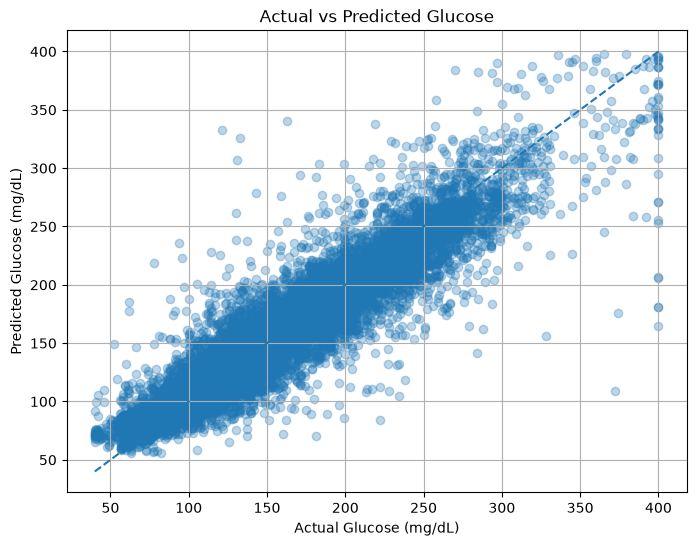

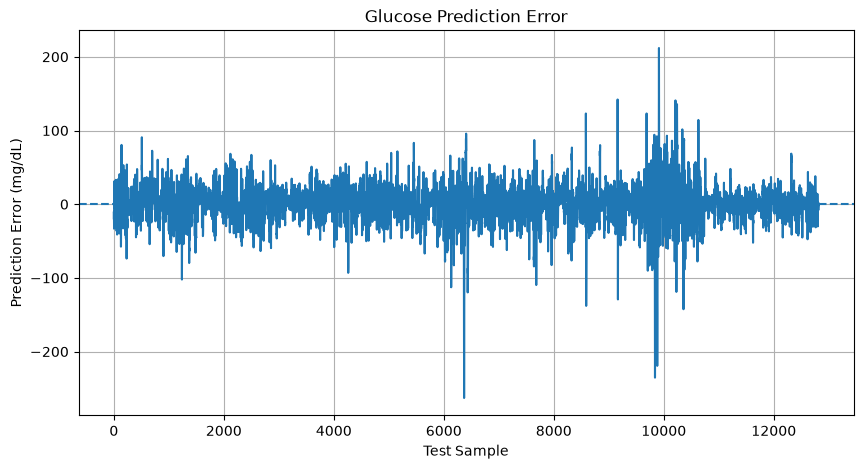

In [106]:
# ============================================
# STEP 18: MODEL VISUALIZATION
# ============================================

import matplotlib.pyplot as plt

# --------------------------------------------
# Plot 1: Actual vs Predicted
# --------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.3
)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Glucose (mg/dL)")
plt.ylabel("Predicted Glucose (mg/dL)")
plt.title("Actual vs Predicted Glucose")

plt.grid(True)
plt.show()


# --------------------------------------------
# Plot 2: Prediction Error
# --------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    comparison["error"].values
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Test Sample")
plt.ylabel("Prediction Error (mg/dL)")
plt.title("Glucose Prediction Error")

plt.grid(True)
plt.show()

In [107]:
# ============================================
# STEP 19: SAVE BASELINE MODEL
# ============================================

import joblib
from pathlib import Path

model_path = Path("../models")

# Create models folder if it doesn't exist
model_path.mkdir(parents=True, exist_ok=True)

# Save model
joblib.dump(
    model,
    model_path / "random_forest_glucose_model.pkl"
)

# Save feature list
joblib.dump(
    feature_columns,
    model_path / "feature_columns.pkl"
)

print("Model saved successfully!")
print(
    "Model path:",
    model_path / "random_forest_glucose_model.pkl"
)

print(
    "Feature list saved:",
    model_path / "feature_columns.pkl"
)


Model saved successfully!
Model path: ../models/random_forest_glucose_model.pkl
Feature list saved: ../models/feature_columns.pkl


In [109]:
# ============================================
# SAVE FINAL MERGED DATASET
# ============================================

from pathlib import Path

processed_path = Path("../data/processed")

# Make sure the folder exists
processed_path.mkdir(
    parents=True,
    exist_ok=True
)

output_path = processed_path / "merged_dataset.csv"

# Save merged dataframe
merged.to_csv(
    output_path,
    index=False
)

print("✅ Merged dataset saved successfully!")
print("Path:", output_path)
print("Shape:", merged.shape)

✅ Merged dataset saved successfully!
Path: ../data/processed/merged_dataset.csv
Shape: (65535, 19)
